# 🎨 Matplotlib & Seaborn — The Super Simple Guide

**Who is this for?** Anyone. You don't need to know anything about data or charts before you start.
Every idea is explained in **small, easy steps**, with examples from **everyday life** (sleep, steps, money in €).

**How to use this notebook**
1. Read the text cells (like this one) **slowly**. 🐢
2. Run the code cells **in order**, from top to bottom. In VS Code / Jupyter, the easiest way is **Run All** ▶️▶️.
3. After each chart, read **"How to read this chart"**. Then try the **✅ Try it yourself** task.
4. At the end of each lesson there is a **⭐ One sentence to remember**. If you remember only that, you're doing great.

### 📚 What's inside

| Part | Lessons |
|---|---|
| **Start here** | The big idea · What is data · Pretend data · The setup code, line by line |
| **Part 1 — Matplotlib ✏️** | 1 Line · 2 Bar & `barh` · 3 Histogram · 4 Scatter · 5 Many charts on one page · 6 Saving |
| **Part 2 — Seaborn 📘** | 7 Line · 8 Bar + error bar · 9 Histogram + KDE · 10 Box plot · 11 Scatter + `hue` · 12 Trend line · 13 Heatmap · 14 Pair plot |
| **Finish** | How to explain any chart · Golden rules · Fixes for old code · Glossary · 14-day plan · Your first chart |

# 🌟 The Big Idea (read this 3 times)

### What is data?

**Data is information you write down about something, so you can look at it later.**

Imagine you have a small notebook in your pocket. Every night, you look at your phone and write down how many steps you walked:

```
Monday     →  5,000 steps
Tuesday    →  7,200 steps
Wednesday  →  3,100 steps
Thursday   →  6,500 steps
Friday     →  8,000 steps
```

**That list is data.** That's all it is.
- **"About something"** = the topic. Here: **your walking**.
- **"Information you write down"** = the list: **5,000, 7,200, 3,100…**

More examples from everyday life:

| What you write down every day | The topic | The data |
|---|---|---|
| Money spent on the metro / bus | Transport | 2.15 €, 2.15 €, 4.30 €, 0 € |
| What time you woke up | Waking up | 6:00, 6:30, 5:45, 7:00 |
| Glasses of water you drank | Drinking water | 4, 6, 3, 8, 5 |
| What you ate for lunch | Lunch | sandwich, pasta, salad, sandwich |

👉 Data can be **numbers** (5,000 steps) **or words** (sandwich, sunny, rainy).

### What is a chart?

**A chart is a picture of data.** Reading a long list of numbers is hard. A picture shows you the story **in one second**:
in the steps example you instantly see that *Wednesday was a lazy day* and *Friday was the most active*.

### Matplotlib and Seaborn

- **Matplotlib** = a **box of crayons and blank paper** ✏️. You can draw anything, but you draw every line yourself.
- **Seaborn** = a **coloring book** 📘. The pictures are already drawn nicely; you just give it your data.
- Seaborn **uses Matplotlib inside**. Same crayons, nicer book. That's why we learn both.

### The 4 questions a chart can answer

| Question | Chart | Everyday example |
|---|---|---|
| How does it **change over time**? | Line | My steps from Monday to Sunday |
| Which group is **bigger**? | Bar | Money spent on food vs transport |
| How **often** does each value happen? | Histogram | How many minutes my bus usually takes |
| Do two things **move together**? | Scatter | More sleep → better mood? |

> ⭐ **One sentence to remember:** "Data is what you write down about something. A chart is a picture of it. First ask your question — the question picks the chart."

# 🎭 Step 0 — Pretend data (and why we use it)

To learn charts we need data. But on day 1 of learning:
- you **don't have** a notebook of your sleep and mood for 28 days, and
- real data from the internet is often **big, messy and confusing**.

So we ask the computer to **invent data that looks like real life**. That's called **pretend data** (the technical name is **synthetic data**).

### 🧸 The toy kitchen
Children learn to cook with a **toy kitchen**: the food isn't real, but the skills are (holding the pan, stirring, serving).
Later they cook real food with the **same skills**. **Pretend data is the toy kitchen of data science.**

### 🔍 The treasure hunt — the best reason of all
Because **we** make the data, **we know the answer**. We can **hide a secret** in it and check if a chart **finds** it.

- 🧸 Hiding a toy in the garden = writing code where **more sleep gives a better mood**.
- 📢 The metal detector = the chart.
- ✅ If the detector beeps in the right place, the tool **works** — and we can trust it on real data later.

(Spoiler: in Lessons 4, 11, 12, 13 and 14 the charts **find** the secret. 🎯)

### Why pretend data is great for learning

| Reason | Why it helps |
|---|---|
| 🆓 Free and fast | No waiting 28 days to collect it |
| 🧹 Clean | No missing days, no mistakes |
| 🔑 The same every time | Thanks to the **seed** (explained below), your charts look exactly like everyone else's |
| 🎯 We know the answer | We can test whether a chart tells the truth |

> ⚠️ **Honesty rule:** when you show a chart to other people, **always say if the data is pretend** ("this is practice data"). Never present invented data as real.

Our pretend data: **one person's daily life for 28 days of October** — sleep, steps, water, mood and money spent (in €).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Same colors in every chart, so the pictures look like a family
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

rng = np.random.default_rng(7)  # same "random" numbers every time you run it
days = pd.date_range("2026-10-01", periods=28, freq="D")
sleep = rng.normal(7, 1, 28).round(1)

life = pd.DataFrame({
    "date": days,
    "weekday": days.day_name().str[:3],
    "weekend": np.where(days.dayofweek >= 5, "Weekend", "Weekday"),
    "sleep_hours": sleep,
    "steps": rng.normal(6500, 1800, 28).round().astype(int),
    "water_glasses": rng.integers(3, 10, 28),
    "mood": np.clip((sleep - 7) * 1.5 + rng.normal(6, 1, 28), 1, 10).round(1),
    "money_spent": rng.gamma(2, 15, 28).round(2),
})
life.head()

,date,weekday,weekend,sleep_hours,steps,water_glasses,mood,money_spent
0,2026-10-01,Thu,Weekday,7.0,6413,5,6.6,19.56
1,2026-10-02,Fri,Weekday,7.3,6704,5,4.5,28.31
2,2026-10-03,Sat,Weekend,6.7,3746,7,5.1,12.10
3,2026-10-04,Sun,Weekend,6.1,5640,9,4.6,29.19
4,2026-10-05,Mon,Weekday,6.5,4739,5,6.5,21.74


## 🔎 The cell above, explained line by line

**This whole cell does one job: it makes pretend data** — a table of 28 days of someone's life. Let's go piece by piece. 🐢

### Part 1 — Bring your tools to the table

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
```

Before you cook, you take your pots out of the cupboard. `import` means **"bring this tool so I can use it"**.

| Tool | What it does | Nickname |
|---|---|---|
| **numpy** | A calculator for numbers; it can also make random numbers | `np` |
| **pandas** | Makes **tables**, like Excel | `pd` |
| **matplotlib.pyplot** | The crayons for drawing charts | `plt` |
| **seaborn** | The coloring book for prettier charts | `sns` |

`as np` gives the tool a **nickname**, so we type `np` instead of `numpy` every time.

### Part 2 — Choose our colors

```python
# Same colors in every chart, so the pictures look like a family
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
```

- A line starting with `#` is a **note for humans** (a *comment*). The computer ignores it.
- `"#2a78d6"` is a **color code** (a *hex code*). Computers name colors with codes, like every phone has a number.
- We store them in easy names, so later we just write `color=BLUE`.

### Part 3 — The seed 🌱

```python
rng = np.random.default_rng(7)
```

`rng` = **random number generator**: a **machine that throws dice** 🎲. **Random** means *you can't guess the next number*.

**The problem:** every time you press Run, random numbers change → your charts change → you can't compare with a friend or check your work. 😵

**The fix — the seed:** the `7` is a **secret code** 🔑. **Same seed → same "random" numbers, every time, on every computer.**

🃏 *Think of a shuffled deck of cards. The seed is a **photo** of the shuffled order: you can put the cards back in exactly that order whenever you want.*

| Seed | Numbers you get |
|---|---|
| `default_rng(7)` | one set of numbers — always the same |
| `default_rng(42)` | a different set — but always the same for 42 |
| `default_rng()` (empty) | new numbers every time (no seed) |

- The number 7 isn't special — any number works. What matters is **keeping the same one**.
- You give the seed **once**. After that, `rng` **remembers** it — like typing your phone password once, then just using the phone.
- Data scientists use seeds so **other people get exactly the same results**.

### Part 4 — Make a calendar

```python
days = pd.date_range("2026-10-01", periods=28, freq="D")
```

"Start on **1 October 2026**, count **28** dates, one each **D**ay." → 1 Oct, 2 Oct … 28 Oct.

### Part 5 — Make up sleep hours: `rng.normal(7, 1, 28)`

```python
sleep = rng.normal(7, 1, 28).round(1)
```

The magic machine 🎰 needs **3 things**:

| Number | Simple meaning | Technical name |
|---|---|---|
| **7** | 🏠 "Give me numbers **close to 7**" — the favorite number, the middle | **mean** |
| **1** | 🚧 "They can go **about 1** away from 7" — how far the fence is | **standard deviation** |
| **28** | 🔢 "Give me **28** numbers" | **size** |

You get numbers like 6.4, 7.2, 8.1, 5.9 — like real sleep, mostly around 7 hours.
`.round(1)` keeps **1 number after the dot** (7.2 instead of 7.2384…).

👉 Full explanation with pictures in **Lesson 3**. We store `sleep` separately because we use it again for mood.

### Part 6 — Build the table

`pd.DataFrame({ ... })` makes a **table** called `life`. Each line inside `{ }` makes **one column**: `"column name": what goes inside`.

| Line | Plain English | Example |
|---|---|---|
| `"date": days` | The 28 calendar dates | 2026-10-01 |
| `"weekday": days.day_name().str[:3]` | The day's name ("Thursday"), first **3 letters** | Thu |
| `"weekend": np.where(days.dayofweek >= 5, "Weekend", "Weekday")` | **If** Saturday or Sunday → "Weekend", **otherwise** "Weekday" | Weekday |
| `"sleep_hours": sleep` | The sleep numbers from Part 5 | 7.0 |
| `"steps": rng.normal(6500, 1800, 28).round().astype(int)` | 28 step counts near 6,500, as **whole numbers** | 6,412 |
| `"water_glasses": rng.integers(3, 10, 28)` | 28 whole numbers from **3 to 9** | 5 |
| `"mood": ...` | Happiness score 1–10 (explained below) | 6.6 |
| `"money_spent": rng.gamma(2, 15, 28).round(2)` | Money per day in €: usually small, sometimes big (explained below) | 24.50 |

#### 📅 Why is Friday a "Weekday"? Python counts from 0!

| Mon | Tue | Wed | Thu | Fri | Sat | Sun |
|---|---|---|---|---|---|---|
| **0** | **1** | **2** | **3** | **4** | **5** | **6** |

`dayofweek >= 5` asks **"is your number 5 or bigger?"** Friday is **4** → no → "Weekday". Only Saturday (5) and Sunday (6) are "Weekend".
Want Friday in the weekend? Change `>= 5` to `>= 4`.

#### 🔢 Why 3 to **9** and not 10?
In Python, the **last number is a stop sign** 🛑 — you stop **before** it. `integers(3, 10)` gives 3…9. (Same rule as `[:7]` in Lesson 5.)

#### 💶 Why `gamma` for money, and not `normal`?

Think about a normal week in France:

| Day | What happened | Spent |
|---|---|---|
| Mon | Baguette + café | 4 € |
| Tue | Lunch at a boulangerie | 9 € |
| Wed | Baguette only | 1.30 € |
| Thu | Lunch + metro ticket | 12 € |
| Fri | Groceries | 25 € |
| **Sat** | **New shoes + dinner with friends** | **110 €** |
| Sun | Croissants | 3 € |

Most days are **small**, a few days are **very big**. `normal` would be wrong here: it spreads numbers **equally on both sides** and could give **−10 €** — impossible! `gamma`:
1. ✅ never goes below 0,
2. ✅ makes most numbers small,
3. ✅ has a **long tail to the right** (a few big days).

```
normal (fair hill):            gamma (leaning hill, long tail):
        ▆▆                        ▆▆
      ▆▆▆▆▆▆                      ▆▆▆▆
    ▆▆▆▆▆▆▆▆▆▆                  ▆▆▆▆▆▆▆
  ▆▆▆▆▆▆▆▆▆▆▆▆▆▆                ▆▆▆▆▆▆▆▆▆▆▆▁▁▁▁▁▁▁
 same on both sides             most days small   few BIG days 👟
```

In `rng.gamma(2, 15, 28)`: **2** = *shape* (how much the hill leans), **15** = *scale* (how big the amounts are), **28** = how many.
**Trick:** shape × scale = the average → 2 × 15 = **about 30 € per day**. `.round(2)` keeps 2 decimals, like a real price (24.50 €).

**Choose the right dice for the right data:**

| Kind of data | Behaves like | Use |
|---|---|---|
| Height, sleep hours, mood | A fair hill, both sides equal | `normal` |
| Money spent, waiting time, house prices | Never below 0, mostly small, sometimes huge | `gamma` |
| Glasses of water, number of children | Whole numbers only | `integers` |

### Part 7 — The mood formula 🧮 (the hidden secret)

```python
"mood": np.clip((sleep - 7) * 1.5 + rng.normal(6, 1, 28), 1, 10).round(1)
```

It looks scary, but it's a **recipe with 5 small steps**. 🍰

**Step 1 — `sleep - 7`: did I sleep more or less than normal (7 h)?**
8.3 h → **+1.3** (more 👍) · 7.0 h → **0** (normal) · 4.5 h → **−2.5** (less 👎)

**Step 2 — `* 1.5`: make the effect stronger.** This is the **"sleep push"**. Think of 1.5 as a **volume button** 🔊: `* 0` = sleep doesn't matter, `* 5` = sleep controls everything.

**Step 3 — `+ rng.normal(6, 1, 28)`: add a normal mood, with surprises.** Everyone has a normal mood of about **6/10**, and life has surprises (rain 🌧️, a nice message 💌) that change mood **for no sleep reason**.

**Step 4 — add them together.** Real days from this data:

| Day | Sleep push | + Base mood | = Mood |
|---|---|---|---|
| 😊 Happiest day (8.3 h) | (8.3 − 7) × 1.5 = **+1.95** | + 5.63 | = **7.58** |
| 😐 Normal day (7.0 h) | **0** | + 6.65 | = **6.65** |
| 😢 Saddest day (4.5 h) | (4.5 − 7) × 1.5 = **−3.75** | + 4.71 | = **0.96** |
| 🤔 Strange day (7.3 h) | **+0.45** | + 4.01 (a bad day for another reason) | = **4.46** |

**Step 5 — `np.clip(..., 1, 10)`: the fence 🚧.** Mood must stay between 1 and 10. Below 1 → becomes 1; above 10 → becomes 10.
That's why the saddest day shows **mood 1**, not 0.96. Then `.round(1)` → 7.58 becomes **7.6**.

```
😴 sleep → (−7) → (×1.5) sleep push → (+ base mood ~6 🎲) → clip 1–10 🚧 → round → 😊 mood
```

| Part of the formula | What you'll see in the charts |
|---|---|
| `(sleep - 7) * 1.5` | 🪜 dots **climb** to the right (more sleep → better mood) |
| `rng.normal(6, 1, 28)` | 🎲 dots **wobble** around the stairs; some strange days appear |

### Part 8 — Look at the first rows

`life.head()` shows the **top 5 rows** of the table — like peeping at the first page of a book.
Each **row** is one day, each **column** is one thing we measured. This kind of table is called a **DataFrame**.

> ⭐ **One sentence to remember:** "This cell brings the tools, chooses colors, and makes a pretend table of 28 days — with one secret hidden inside: more sleep gives a better mood."

### 🧪 Try it yourself — see the seed with your own eyes

Run the next cell **3 times**. The first line never changes (seed 7). The second line changes every time (no seed).

In [2]:
print("With seed 7:", np.random.default_rng(7).normal(35, 7, 5).round())
print("No seed:    ", np.random.default_rng().normal(35, 7, 5).round())

With seed 7: [35. 37. 33. 29. 32.]
No seed:     [33. 30. 43. 27. 42.]


### 🧪 Try it yourself — see why money uses `gamma`

1,000 pretend days of spending: smallest is never below 0 €, average is close to 2 × 15 = 30 €, and there are a few very big days.
Change the shape from `2` to `10` — the hill leans less and starts to look like `normal`.

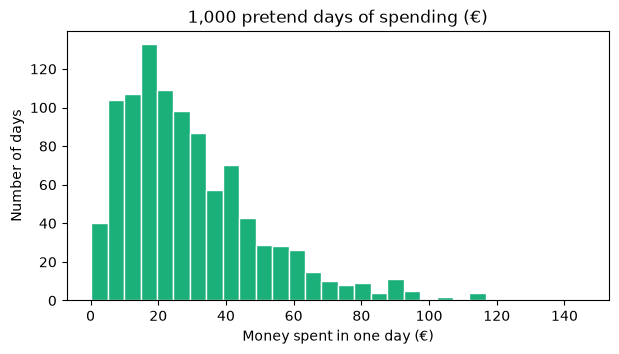

Smallest day: 0.21 €
Average day:  29.6 €
Biggest day:  145.9 €


In [3]:
money = np.random.default_rng(1).gamma(2, 15, 1000)

plt.figure(figsize=(7, 3.5))
plt.hist(money, bins=30, color=AQUA, edgecolor="white")
plt.title("1,000 pretend days of spending (€)")
plt.xlabel("Money spent in one day (€)")
plt.ylabel("Number of days")
plt.show()

print("Smallest day:", money.min().round(2), "€")
print("Average day: ", money.mean().round(2), "€")
print("Biggest day: ", money.max().round(2), "€")

---
# PART 1 — MATPLOTLIB (the crayons ✏️)

### The 3-step recipe (every Matplotlib chart)

1. **Get paper** → `fig, ax = plt.subplots()`
2. **Draw** → `ax.plot(...)`, `ax.bar(...)`, `ax.hist(...)`, `ax.scatter(...)`
3. **Write the names** → title, x label, y label → then `plt.show()`

### 📄 What are `fig` and `ax`?

`plt.subplots()` gives you **two things**:

| Name | What it is | Simple picture |
|---|---|---|
| **`fig`** (*figure*) | The **whole sheet of paper** | 📄 a blank A4 sheet |
| **`ax`** (*axes*) | The **box on the paper where you draw**, with its two rulers | 🖼️ the frame you draw inside |

```
┌──────────────── fig (the whole paper) ────────────────┐
│        My steps every day in October   ← title        │
│      ┌────────────── ax ───────────────┐              │
│ Steps│        •                         │              │
│      │   •   / \     •                  │              │
│      │  / \ /   \   / \   •             │              │
│      │ •   •     • •   • / \            │              │
│      └──────────────────────────────────┘              │
│                     Day                                │
└────────────────────────────────────────────────────────┘
```

- It's called **axes** because the box has **two rulers** (two *axes*): the **x-axis** at the bottom ↔️ and the **y-axis** on the left ↕️.
- Almost everything is done **to `ax`** (draw, title, labels), because that's where the drawing lives. `fig` is used for things about the **whole paper** (tilting dates, saving).
- One paper can hold **many boxes** — see Lesson 5.

> ⭐ "Paper, draw, name it. `fig` is the paper, `ax` is where you draw."

## 1. Line chart — *How does it change over time?*

🧒 **Like:** drawing a dot for every day and joining the dots with a string.

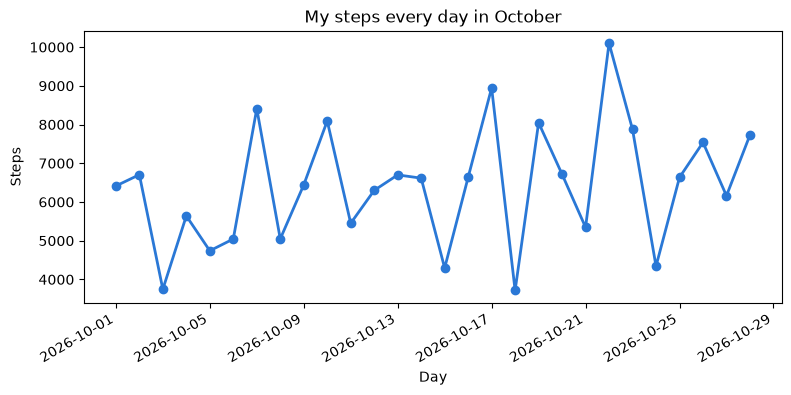

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))                      # 1. paper
ax.plot(life["date"], life["steps"], color=BLUE, linewidth=2, marker="o")  # 2. draw
ax.set_title("My steps every day in October")              # 3. names
ax.set_xlabel("Day")
ax.set_ylabel("Steps")
fig.autofmt_xdate()          # tilts the dates so they don't crash into each other
plt.show()

**Line by line**
- `figsize=(9, 4)` → the paper is **9 wide, 4 tall** (in inches) — a long paper, good for many days.
- `ax.plot(x, y)` → dates at the bottom, steps going up. `linewidth=2` = line thickness. `marker="o"` = a **dot on every day** (`"s"` = square, `"^"` = triangle, `"*"` = star).
- `fig.autofmt_xdate()` → the dates are long, so it **tilts** them like books leaning on a shelf 📚.
- `plt.show()` → "Computer, show me my drawing!"

✅ **Try it yourself:** change `"steps"` to `"sleep_hours"`. Change `marker="o"` to `marker="s"`. What changed?

> ⭐ "A line chart shows how one thing changes over time."

## 2. Bar chart — *Which group is bigger?*

🧒 **Like:** building towers with blocks. The taller tower wins.

Here we use **`barh`** = **bar, horizontal**: bars that **lie down** 🛌 instead of standing up 🏢.

```
ax.bar  (standing)            ax.barh  (lying down)
  █                          Food        ████████████
  █  █                       Transport   █████
  █  █     █                 Phone/Data  ██
  █  █  █  █                 Fun         ████
 Food Trans Phone Fun
```
Same data, same job (comparing groups). Only the direction changes.

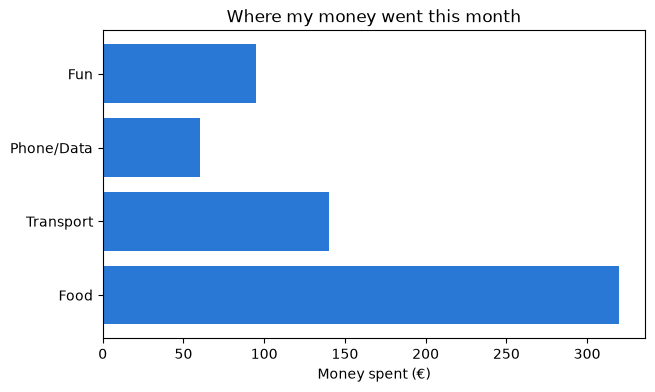

In [5]:
spending = {"Food": 320, "Transport": 140, "Phone/Data": 60, "Fun": 95}

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(spending.keys(), spending.values(), color=BLUE)
ax.set_title("Where my money went this month")
ax.set_xlabel("Money spent (€)")
plt.show()

**Line by line**
- `spending = {...}` → a little **shopping list** called a *dictionary*: each pair is `"thing": money`. Words first, numbers second.
- `spending.keys()` → the **words** (Food, Transport…). `spending.values()` → the **numbers** (320, 140…).
- **The bigger the money, the longer the bar.**

⚠️ **Watch out — the rulers swap places when bars lie down:**

| | `bar` (standing) | `barh` (lying down) |
|---|---|---|
| Group names (Food, Transport…) | bottom (x) | left side (y) |
| Numbers (€) | left side (y) | bottom (x) |

So with `barh`, the € label goes on **`set_xlabel`**, not `set_ylabel`. **Easy rule:** put the € label next to the € numbers.

**When should I use `barh`?**
1. When the names are **long** — standing bars squash them.
2. When there are **many groups** — lying bars read like a list.
3. For a **ranking** (top 10). `barh` draws the first item at the **bottom**, so sort from smallest to biggest to put the winner on top 🥇:
   `sorted_spending = dict(sorted(spending.items(), key=lambda item: item[1]))`

**In Seaborn** there's no `barh` — just **swap x and y**: `sns.barplot(x=list(spending.values()), y=list(spending.keys()))`.

**What the chart tells us:** most of the money went on **food**. 🍞

✅ **Try it yourself:** add `"Rent": 400` to the dictionary. Change `barh` back to `bar` — and remember to move the € label to `set_ylabel`!

> ⭐ "`barh` is a bar chart lying down: use it for long names, many groups, or a ranking."

## 3. Histogram — *How often does each value happen?*

🧒 **Like:** sorting sweets into jars by size, then looking at which jar is the fullest. 🫙

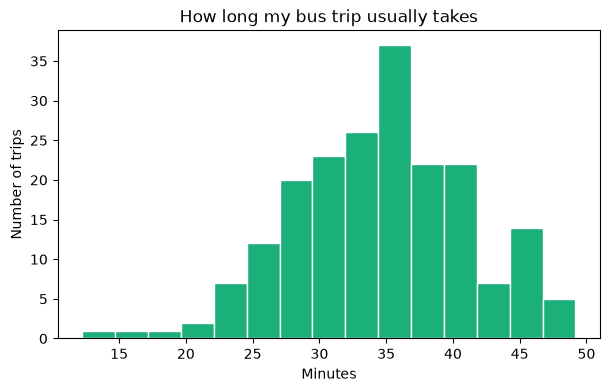

In [6]:
bus_minutes = rng.normal(35, 7, 200)   # 200 trips to work

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bus_minutes, bins=15, color=AQUA, edgecolor="white")
ax.set_title("How long my bus trip usually takes")
ax.set_xlabel("Minutes")
ax.set_ylabel("Number of trips")
plt.show()

### 🔎 What does `rng.normal(35, 7, 200)` mean?

**"Make up 200 bus trips. Most take about 35 minutes, usually give or take 7 minutes."** 🚌

Think of a **magic machine** 🎰. You tell it 3 things:

| Number | You say to the machine | In the bus story | Technical name |
|---|---|---|---|
| **35** | "I like 35 — give me numbers **close to 35**" 🏠 | A normal trip takes 35 min | **mean** |
| **7** | "You can go **about 7** away" 🚧 | Some days a bit faster or slower | **standard deviation** |
| **200** | "Give me **200** numbers" 🔢 | You took the bus 200 times | **size** |

**The 7 is a fence, like a house with a garden:**
```
   🚧                🏠                🚧
   28                35                42
```
- About **7 out of 10** trips land between 28 and 42 (35 ± 7).
- About **19 out of 20** trips land between 21 and 49 (35 ± 14).
- A 60-minute trip almost never happens.

| Code | Meaning |
|---|---|
| `rng.normal(35, 1, 200)` | fence very close → trips are almost always 34–36 min → a **reliable** bus 😊 |
| `rng.normal(35, 7, 200)` | a **normal** bus |
| `rng.normal(35, 15, 200)` | fence very far → trips anywhere from 20 to 50 min → a **crazy** bus 😵 |

**How the numbers are related:** 35 and 7 work **together** (35 says *where*, 7 says *how spread out*). 200 is on its own: it only says *how many*.

### ❌ It is NOT steps of 7!
A common mistake: thinking it counts 35, 42, 49, 56… **No.** It gives **mixed-up numbers near 35, in no order, with decimals**:
`36.2, 31.5, 40.1, 34.8, 29.3, 37.6 …` — like **rain drops** 🌧️ around a house: many near the house, few far away.
If you **want** steps of 7, that's a different tool: `np.arange(35, 80, 7)` → 35, 42, 49, 56, 63, 70, 77 (stairs 🪜).

### 🌱 Where is the seed here?
**Not in this line.** The seed is in `rng = np.random.default_rng(7)` at the top. `rng` already remembers it.
⚠️ Don't mix the two 7s: in `default_rng(7)` the 7 is the **seed** 🔑; in `normal(35, 7, 200)` the 7 is the **fence** 🚧. Same number by accident.

### 📊 How to read this chart
- **Bottom:** minutes. **Left:** number of trips. Each bar is a **jar** for a range of minutes.
- `bins=15` → **15 jars**. `edgecolor="white"` → white lines between jars.
- The tallest jar is near **35 minutes** — the usual trip. Few trips are very short or very long.
- The shape is a **hill** 🔔 — tall in the middle, low at the sides. This shape is called the **normal distribution** or **bell curve**.

✅ **Try it yourself:**
1. Change `bins=15` to `bins=5`, then `bins=40`. More jars = more detail.
2. Change the 7 to 1, then 15. Watch the hill get thin or fat.
3. Compare rain and stairs: `print(np.random.default_rng(7).normal(35, 7, 10).round(1))` vs `print(np.arange(35, 80, 7))`.

> ⭐ "`normal(35, 7, 200)` = 200 numbers, close to 35, usually not more than about 7 away. The 7 is a fence, not a jump."

## 4. Scatter plot — *Do two things move together?*

🧒 **Like:** every day is one dot. Left-right = how much I slept. Up-down = how happy I was.
If the dots climb up like stairs, the two things go together.

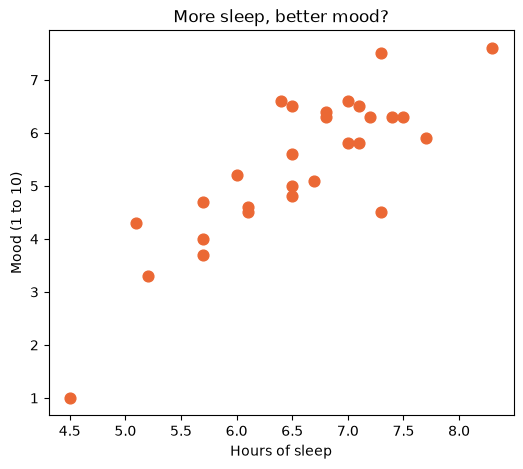

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(life["sleep_hours"], life["mood"], color=ORANGE, s=60)
ax.set_title("More sleep, better mood?")
ax.set_xlabel("Hours of sleep")
ax.set_ylabel("Mood (1 to 10)")
plt.show()

- `s=60` → the **size** of each dot.
- The dots go **up to the right** → on days with more sleep, mood was better. 🎯 That's the secret we hid in the mood formula.
- ⚠️ This does **not prove** sleep *causes* good mood. It only shows they **move together**. (More in Lesson 11.)

> ⭐ "Each dot is one day. If the dots climb like stairs, the two things go up together."

## 5. Many charts on one paper — `subplots`

🧒 **Like:** a page in a photo album with 4 photos on it. 📸📸📸📸

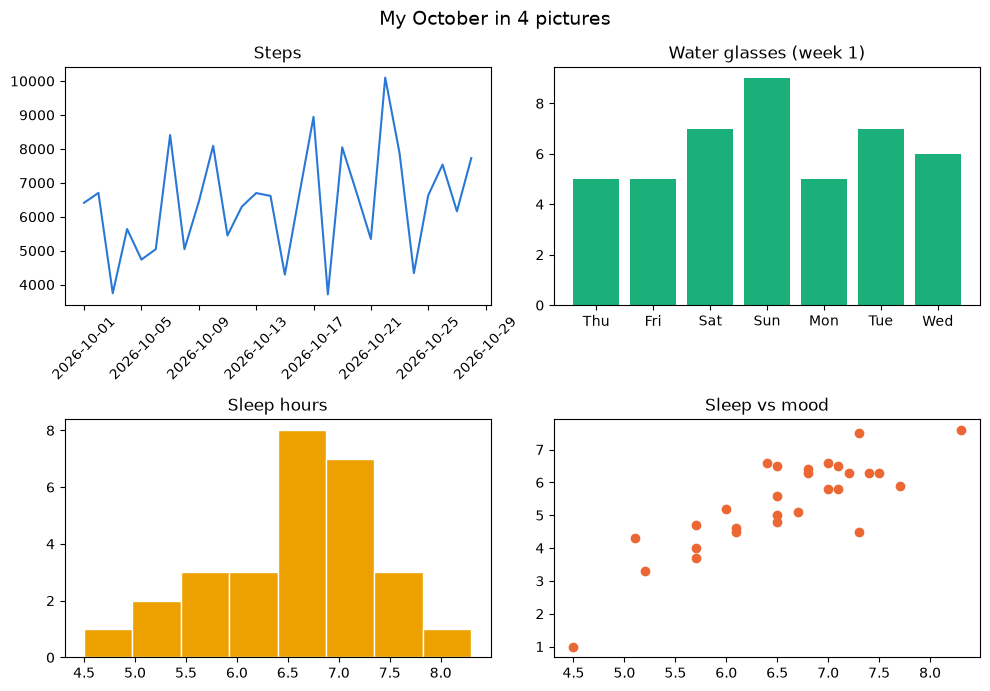

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))   # 2 rows, 2 columns of boxes

axes[0, 0].plot(life["date"], life["steps"], color=BLUE)
axes[0, 0].set_title("Steps")
axes[0, 1].bar(life["weekday"][:7], life["water_glasses"][:7], color=AQUA)
axes[0, 1].set_title("Water glasses (week 1)")
axes[1, 0].hist(life["sleep_hours"], bins=8, color=YELLOW, edgecolor="white")
axes[1, 0].set_title("Sleep hours")
axes[1, 1].scatter(life["sleep_hours"], life["mood"], color=ORANGE)
axes[1, 1].set_title("Sleep vs mood")

axes[0, 0].tick_params(axis="x", rotation=45)
fig.suptitle("My October in 4 pictures", fontsize=14)
fig.tight_layout()          # stops the boxes from bumping into each other
plt.show()

### Step 1 — Paper with 4 boxes
`plt.subplots(2, 2, figsize=(10, 7))` → **2 rows × 2 columns = 4 boxes** on a bigger paper.
`fig` = the paper; `axes` = **all 4 boxes together** (`ax` = one box, `axes` = many boxes).

### Step 2 — Every box has an address: `axes[row, column]`
Python **counts from 0** (like the days: Monday = 0).
```
              column 0        column 1
   row 0    │ axes[0,0] │   │ axes[0,1] │      ↖️ top left    ↗️ top right
   row 1    │ axes[1,0] │   │ axes[1,1] │      ↙️ bottom left ↘️ bottom right
```
**First number = row (up/down), second = column (left/right)** — like a cinema seat 🎬: row first, then seat.

### Step 3 — Draw in each box
| Box | Chart | Notes |
|---|---|---|
| ↖️ `axes[0, 0]` | Line of steps 📈 (blue) | |
| ↗️ `axes[0, 1]` | Bars of water glasses 📊 (aqua) | `[:7]` = only the first week (see below) |
| ↙️ `axes[1, 0]` | Histogram of sleep 🫙 (yellow) | `bins=8` = 8 jars; white lines between them |
| ↘️ `axes[1, 1]` | Scatter of sleep vs mood ⚫ (orange) | |

#### What is `[:7]`? — "take only the first 7"
It takes positions **0, 1, 2, 3, 4, 5, 6** = **7 items**. The number after `:` is a **stop sign** 🛑 — you stop **before** it.
```
position:   0    1    2    3    4    5    6  │ 7    8   ...  27
           🍬   🍬   🍬   🍬   🍬   🍬   🍬  │🛑   🍬  ...  🍬
           └──────── you take these ───────┘ └─ you leave these ─┘
```
Why? 28 bars would be squashed. 7 bars fit nicely. The chart starts on **Thu** because 1 October 2026 is a Thursday.
**Trick:** stop − start = how many you get → `[7:14]` = week 2, `[14:21]` = week 3, `[21:28]` = week 4.

### Step 4 — Tidy up
- `axes[0, 0].tick_params(axis="x", rotation=45)` → in the top-left box, **tilt the long dates** 45° so they don't crash 💥.
- `fig.suptitle(...)` → one **big title for the whole paper** ("sup" = *super*, the boss title 👑). `set_title` = title for **one box**.
- `fig.tight_layout()` → moves the boxes a little so titles and labels don't bump into each other (🧍 🧍 "one step apart, please!").

✅ **Try it yourself:** change `[:7]` to `[7:14]` in **both places** to see week 2.

> ⭐ "`subplots(2, 2)` gives 4 boxes, and `axes[row, column]` (counting from 0) tells Python which box to draw in."

## 6. Save your chart as a picture

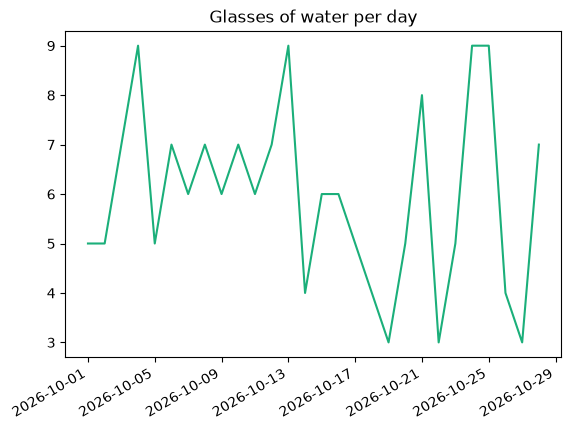

In [9]:
fig, ax = plt.subplots()
ax.plot(life["date"], life["water_glasses"], color=AQUA)
ax.set_title("Glasses of water per day")
fig.autofmt_xdate()
fig.savefig("my_water_chart.png", dpi=150, bbox_inches="tight")   # saved next to this notebook
plt.show()

- `fig.savefig("my_water_chart.png")` → saves the **whole paper** as an image file next to this notebook.
- `dpi=150` → picture quality (dots per inch). Higher = sharper.
- `bbox_inches="tight"` → cuts away the extra white border.
- Always call `savefig` **before** `plt.show()`.

---
# PART 2 — SEABORN (the coloring book 📘)

### Why Seaborn is easier
- You give it the **whole table** (`data=life`) and just say the **column names**.
- It adds nice colors, averages, error bars and legends **for you**.
- Same recipe every time: `sns.CHART(data=table, x="column", y="column")`

🍽️ *Like a restaurant: with Matplotlib you go to the kitchen and bring the food yourself; with Seaborn you give the waiter the menu (`data=life`) and say what you want (`x=..., y=...`).*

### 🎨 Choose the style of the paper
The next cell makes every chart clean, with soft grey grid lines (like a school exercise book 📓).

> ⚠️ **If your charts suddenly look different** (no grid lines, black edges around bars), you probably **skipped this cell**.
> When the notebook restarts, Python **forgets everything** 🧠💨 — use **Run All** to run every cell in order.

In [10]:
sns.set_theme(style="whitegrid")   # make every chart clean and soft

## 7. `sns.lineplot` — the line, the easy way

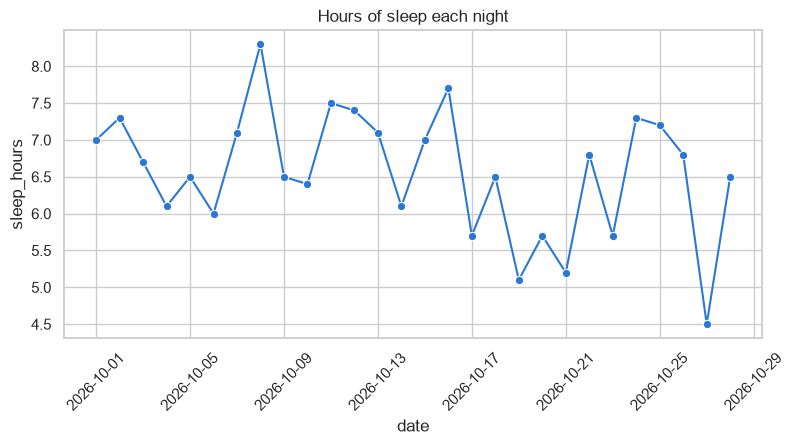

In [11]:
plt.figure(figsize=(9, 4))
sns.lineplot(data=life, x="date", y="sleep_hours", color=BLUE, marker="o")
plt.title("Hours of sleep each night")
plt.xticks(rotation=45)
plt.show()

**Line by line**
- `plt.figure(figsize=(9, 4))` → "give me a sheet of paper". There's **no `fig, ax`** here: Python **remembers the current paper** for us.
- `sns.lineplot(data=life, x="date", y="sleep_hours", ...)` → use the table `life`; the **date** column at the bottom, the **sleep_hours** column going up; blue; a dot on every night.
  - 🎁 **Bonus:** Seaborn writes the axis names for you ("date", "sleep_hours").
- `plt.title(...)` → we have no `ax`, so we ask `plt` to put a title on the current chart.
- `plt.xticks(rotation=45)` → **xticks** = the little labels at the bottom (the dates). Tilt them 45° so they don't crash.

**Same chart, two ways:**

| Step | Matplotlib ✏️ (Lesson 1) | Seaborn 📘 (this lesson) |
|---|---|---|
| Paper | `fig, ax = plt.subplots(...)` | `plt.figure(...)` |
| Draw | `ax.plot(life["date"], life["steps"])` | `sns.lineplot(data=life, x="date", y="sleep_hours")` |
| Axis names | you write them | ✨ written for you |
| Title | `ax.set_title(...)` | `plt.title(...)` |
| Tilt dates | `fig.autofmt_xdate()` | `plt.xticks(rotation=45)` |

**Reading it:** each dot is one night. High dot = slept a lot; low dot = slept a little. Find your best and worst night. 🌙

> ⭐ "With Seaborn, you give the whole table and say the column names, and it draws the chart for you."

## 8. `sns.barplot` — Seaborn finds the average for you

Do I walk more on weekdays or weekends? Seaborn **adds up and divides** (finds the average) by itself.

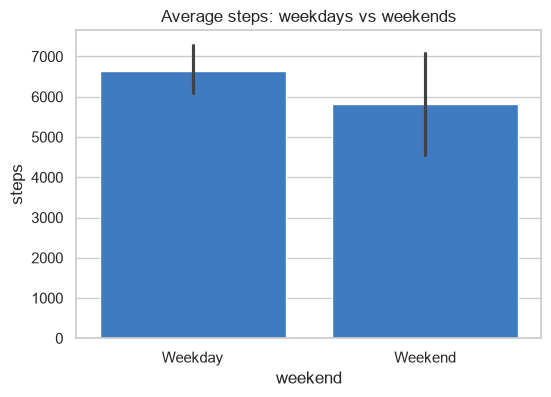

In [12]:
plt.figure(figsize=(6, 4))
sns.barplot(data=life, x="weekend", y="steps", color=BLUE)
plt.title("Average steps: weekdays vs weekends")
plt.show()

### 📏 The black line on top of each bar — the error bar

It's the **thin dark stick standing on top of each bar** (half above the top of the bar, half below).

- The **blue bar** = the **average** for this month.
- The **black line** = **how sure we are** about that average.

**What the line says exactly:** *"The **real** average is **probably** somewhere between the bottom and the top of this line."*
We only looked at **one month**; next month would be a bit different (rain, holidays, sick days…). The line is a guess about you **in general**.

| Bar | The bar says | The black line says |
|---|---|---|
| Weekday | "This month: **6,642** steps on an average weekday" | "A normal weekday for me is probably between **~6,050 and ~7,280**" |
| Weekend | "This month: **5,820** steps on an average weekend day" | "A normal weekend day is probably between **~4,600 and ~7,080**" |

### 🎒 How Seaborn draws the line — the bag game
1. Write each weekend day's steps on a paper and put the **8 papers in a bag**.
2. Pick a paper, write it down, **put it back**. Do it 8 times (you can pick the same day twice). Calculate the average.
3. Play this game **1,000 times** → 1,000 averages.
4. Line them up from smallest to biggest, **throw away the 25 smallest and 25 biggest** ✂️, keep the **middle 950**.
5. The black line goes from the smallest to the biggest of those 950. That's why it's called **95%**.

### 🔍 Why is the Weekend line longer?
- **Weekdays: 20 days**, mostly similar → averages stay close → **short line** = sure ✅
- **Weekends: only 8 days**, very different (3,715 to 8,946) → averages jump around → **long line** = not sure 🤷

🍕 *Ask 20 friends about a pizza shop and most say "good" → you're sure. Ask 8 friends and they disagree → you're not sure.*

### 🧠 The important lesson
The two black lines **overlap** (both cover ~6,050–7,080). So **we can't be sure** weekdays are really different from weekends — it might be luck.
👩‍🔬 A good data scientist says: *"I walked a bit more on weekdays, **but** with only 4 weeks of data I'm not sure the difference is real."*

| Easy words | Technical words |
|---|---|
| The black line | **error bar** |
| "The real average is probably here" | **95% confidence interval** |
| The bag game | **bootstrapping** |

To remove the line: `sns.barplot(..., errorbar=None)` — but keeping it is more **honest**. 👍

> ⭐ "The bar is the average; the black line shows how sure we are. Short line = sure, long line = not sure."

In [13]:
# Check the numbers behind the bars: how many days, and the average, for each group
life.groupby("weekend")["steps"].agg(["count", "mean"]).round(0)

,count,mean
weekend,,
Weekday,20,6642.0
Weekend,8,5820.0


## 9. `sns.histplot` — how often + a smooth hill line (KDE)

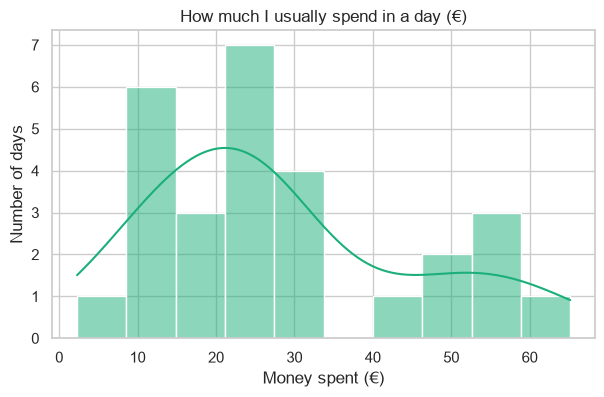

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(data=life, x="money_spent", bins=10, kde=True, color=AQUA)
plt.title("How much I usually spend in a day (€)")
plt.xlabel("Money spent (€)")
plt.ylabel("Number of days")
plt.show()

### 📊 How to read it
- **Bottom ruler:** how many **euros** spent in one day (little on the left, a lot on the right).
- **Left ruler:** **how many days** (the technical word Seaborn uses is *Count*).
- Each bar is a **jar** 🫙 for a price range. Every day goes into the jar that matches what was spent. **Taller bar = more days.**

| Jar (€ per day) | Days | Meaning |
|---|---|---|
| ~2 – 8 € | 1 | one very cheap day 🥖 |
| ~8 – 15 € | 6 | cheap days ☕ |
| ~15 – 21 € | 3 | |
| **~21 – 27 €** | **7** 🏆 | **the most common amount** |
| ~27 – 34 € | 4 | |
| ~34 – 40 € | 0 | an **empty jar** — no day landed here |
| ~40 – 65 € | 7 | the big days 🛍️ (shopping, going out) |

1 + 6 + 3 + 7 + 4 + 0 + 7 = **28 days** ✅

**What it tells us**
1. Most days (20 of 28) cost **8 – 34 €**; the most common is **21 – 27 €**.
2. About **once a week** there's a **big day of 40 – 65 €**.
3. The chart **leans left with a tail to the right** — exactly what `gamma` makes. The chart proves the code did its job. ✅
4. 💡 **The useful lesson:** to save money, don't worry about the small days — **watch the big days**.

### 〰️ The green curvy line: the KDE

**KDE = Kernel Density Estimate.** Let's understand how it's made with the **sand game** 🏖️:
1. Imagine a sandbox with a ruler from 0 € to 65 €.
2. For **each day**, pour **one small cup of sand** at the amount spent. Each cup makes a **small soft hill** ⛰️.
3. Where many days are close together, the small hills **pile up** into a big hill 🏔️.
4. Look at the top of the sand from the side — **that outline is the KDE line**.

```
          ▃▅▇█▇▅▃
       ▁▃▅▇██████▇▅▃▁          ▁▃▄▄▄▃▁
   0 ─────────────────────────────────────── 65 €
             20                    50
      big hill: normal days    small bump: big days
```

| Letter | Word | Easy meaning |
|---|---|---|
| **K** | Kernel | the **small hill** of sand for one day |
| **D** | Density | **how crowded** an area is |
| **E** | Estimate | a **good guess**, not exact |

**Why use KDE if we already have bars?**
1. Bars **change** when you change the number of jars (`bins`) — the KDE doesn't.
2. It's easier for the eyes: one smooth shape instead of corners and gaps.
3. It's easy to **compare groups**: `sns.kdeplot(data=life, x="money_spent", hue="weekend", fill=True)`.

**⚠️ Be careful with KDE**
1. It's a **guess** — with only 28 days, a rough one.
2. Drawn alone (`sns.kdeplot`), the sand can **spill past the edges**, e.g. below 0 € — impossible! Always look at the real bars too.
3. With `histplot(kde=True)` the line is stretched to fit the bars. With `sns.kdeplot` alone the left ruler says *Density* (small numbers like 0.02). **Only the shape matters.**

| | Histogram 🫙 | KDE 〰️ |
|---|---|---|
| Made of | jars (bars) | small sand hills added together |
| Shows | exact counts | the smooth shape |
| Changes with `bins`? | yes | no |

👉 **Best: use both** (`kde=True`) — bars for the facts, line for the shape.

> ⭐ "A histogram puts days into jars: tall jar = it happened often. KDE puts a small sand hill on every day and adds them up; the top of the sand is the smooth line."

### 🧪 Try it yourself — the size of each sand hill: `bw_adjust`

| `bw_adjust` | Each hill is… | The line looks… |
|---|---|---|
| 0.3 | thin and pointy | too bumpy — follows every single day 😬 |
| 1 (default) | medium | just right 👍 |
| 3 | wide and flat | too smooth — hides the small bump at 50 € 😴 |

Like Goldilocks 🐻: not too bumpy, not too smooth. Which of the 3 charts tells the truest story?

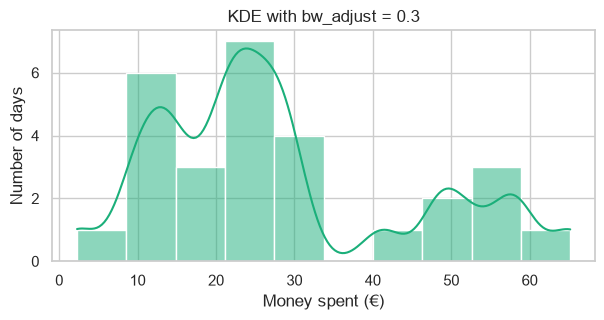

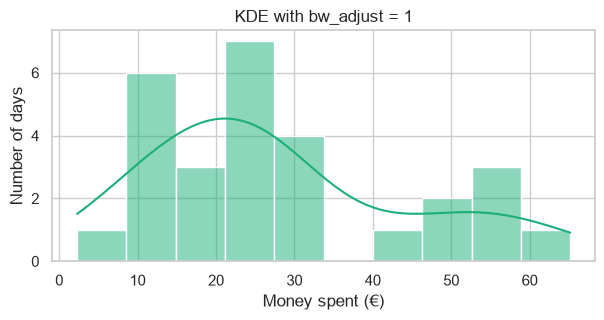

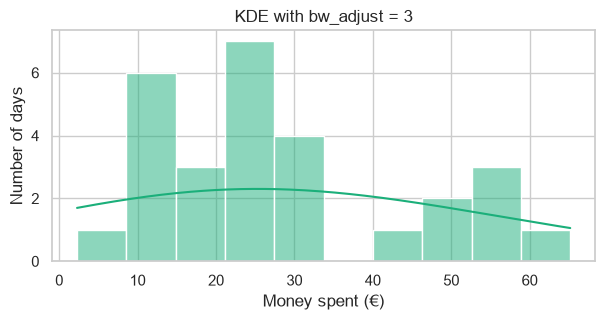

In [15]:
for bw in [0.3, 1, 3]:
    plt.figure(figsize=(7, 3))
    sns.histplot(data=life, x="money_spent", bins=10, kde=True,
                 kde_kws={"bw_adjust": bw}, color=AQUA)
    plt.title(f"KDE with bw_adjust = {bw}")
    plt.xlabel("Money spent (€)")
    plt.ylabel("Number of days")
    plt.show()

## 10. `sns.boxplot` — the 5-number summary in one picture

🧒 **Like:** lining up all the days from smallest to biggest, like children by height.

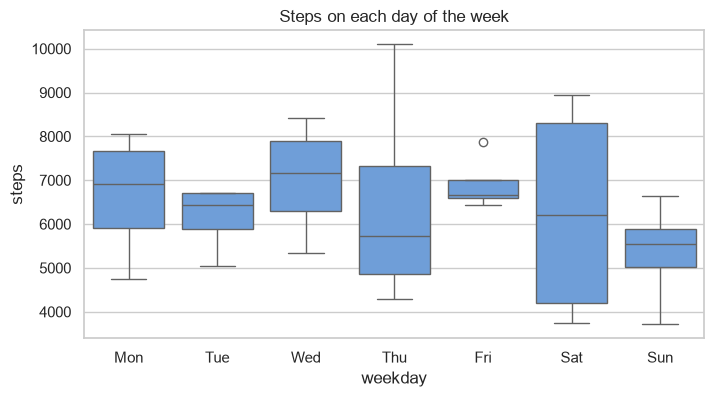

In [16]:
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(8, 4))
sns.boxplot(data=life, x="weekday", y="steps", order=order, color="#5d9cea")
plt.title("Steps on each day of the week")
plt.show()

### 📦 How to read ONE box — Wednesday
The 4 Wednesdays were **5,345 · 6,615 · 7,729 · 8,410** steps.
```
         8,410  ─┬─  ← top whisker: the BIGGEST normal day
        ┌────────┐   ← top of the box
 7,172  ├────────┤   ← the LINE inside: the MIDDLE day ⭐
        └────────┘   ← bottom of the box
         5,345  ─┴─  ← bottom whisker: the SMALLEST normal day
```

| Part | Technical name | Easy meaning |
|---|---|---|
| Line inside the box | **median** | the **middle day**: half the days above, half below ⭐ |
| The box | **interquartile range (IQR)** | where the **middle half** of the days are — the "normal" days |
| Thin lines | **whiskers** 🐱 | how far the normal days go |
| A lonely dot ⚪ | **outlier** | a **strange day**, very different from the others |

`order=[...]` puts the days in calendar order (otherwise Seaborn uses the order it finds them).

### 🔍 Reading the whole picture
| Day | Middle line | Box | What it says |
|---|---|---|---|
| Mon | ~6,900 | medium | a good walking day |
| Tue | ~6,400 | small | quite regular |
| **Wed** | **~7,170** 🏆 | medium | **highest line — best walking day** |
| Thu | ~5,700 | big | up and down; one Thursday hit **10,101** |
| **Fri** | ~6,700 | **tiny** | very regular… except **one dot** ⚪ (7,872) |
| **Sat** | ~6,200 | **huge** | unpredictable: 3,700 to 8,900 (sofa day 🛋️ or shopping day 🛍️) |
| **Sun** | **~5,550** 🐌 | small | **lowest line — laziest day** |

**The Friday dot:** three Fridays were very close (6,441 – 6,704), so the box is tiny. One Friday (7,872) was much bigger, so Seaborn marks it as a strange day ⚪.

### 🗣️ How to explain a box plot — always in this order
| Order | Look at | Say | It answers |
|---|---|---|---|
| 🥇 | **Middle lines** | "Usually this day is highest, this one lowest." | What's normal? |
| 🥈 | **Box sizes** | "This day is regular, this one changes a lot." | Can I trust the middle line? |
| 🥉 | **Dots** | "Here's a strange day." | Did anything unusual happen? |

Why not only the middle line? Saturday's line (~6,200) looks ordinary, but its **huge box** shows Saturdays are either very lazy or very active. **The middle line tells you WHERE; the box tells you HOW SURE.**

### ⚠️ Only 4 days per box!
28 days = 4 weeks → each box is made from **only 4 days**. One strange day changes a box a lot.
👩‍🔬 *"Wednesday **looks like** my best day and Sunday my laziest, **but** with only 4 weeks I need more data to be sure."*

**Bar chart vs box plot:** a bar shows **one** number (the average); a box shows **five** (smallest, bottom of box, middle, top of box, biggest) plus strange days.

> ⭐ "The line in the box is the usual day, the box is the normal days, the whiskers are the edges, and a dot is a strange day. Explain: middle lines → box sizes → dots."

## 11. `sns.scatterplot` with `hue` — color the dots by group

`hue` = "paint each group a different color". This is Seaborn's superpower. 🎨

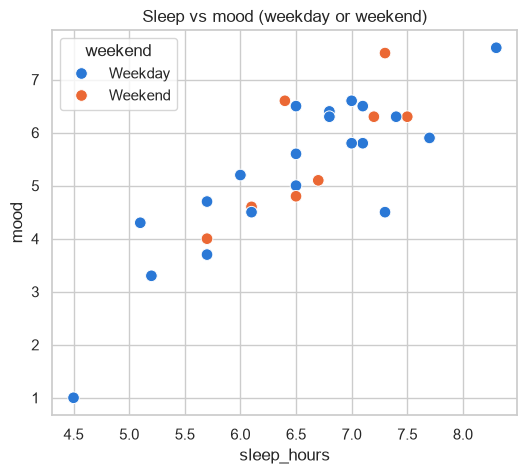

In [17]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=life, x="sleep_hours", y="mood", hue="weekend",
                palette={"Weekday": BLUE, "Weekend": ORANGE}, s=70)
plt.title("Sleep vs mood (weekday or weekend)")
plt.show()

### How to read it
- **One dot = one day** (28 dots).
- **Left ↔ right:** hours of sleep 😴. **Down ↕ up:** mood (1–10) 😊.
- 🔵 blue = weekday, 🟠 orange = weekend. The little box (the **legend** 🗺️) is the key, like on a map.
- `palette={...}` chooses which color each group gets. `s=70` = dot size.

### Some dots
- 😢 **Saddest** (bottom left): 4.5 h sleep, mood 1 — very little sleep, very sad.
- 😊 **Happiest** (top right): 8.3 h sleep, mood 7.6.
- 🤔 **Strange** (blue, 7.3 h, mood 4.5): slept well but wasn't happy — something else happened. Sleep isn't the only thing that changes mood.

### The big pattern
The dots **climb like stairs** 🪜 ↗️ → **on days with more sleep, mood was usually better.**
The 🟠 orange dots are **mixed in** with the blue ones on the same stairs → **weekend or weekday doesn't change the pattern.**

### ⚠️ Together ≠ causes
The dots climb together, but that **doesn't prove** sleep **causes** good mood. Maybe:
- sleep makes you happy, **or**
- being happy helps you sleep, **or**
- something else (no stress 🧘) causes both.

A data scientist says **"they go together"** ✅, not **"one causes the other"** ❌. (Technical words: *correlation is not causation*.)

> ⭐ "Each dot is one day. If the dots climb like stairs, the two things go up together — but that doesn't prove one causes the other."

## 12. `sns.regplot` — draw the trend line for you

`regplot` = **reg**ression **plot**: "draw the dots **and** the best straight line through them".

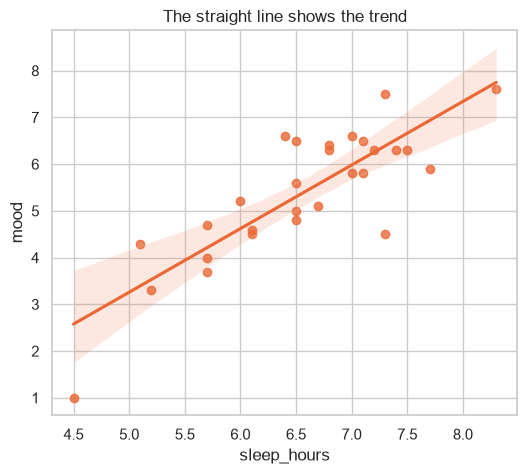

In [18]:
plt.figure(figsize=(6, 5))
sns.regplot(data=life, x="sleep_hours", y="mood", color=ORANGE)
plt.title("The straight line shows the trend")
plt.show()

### 📏 The orange line — the trend
Imagine the dots are people standing in a field 🧍🧍🧍. You must lay **one straight stick** through the field, as close as possible to **everybody**.
Some people are above it, some below. The best stick is the one where people are, all together, the least far away. **That stick is the orange line.**

It goes **up to the right**: *the more you sleep, the better your mood, usually.*

**Read the line like a ruler** 📐 — pick a sleep number at the bottom, go up to the line, look left:

| Sleep | Mood on the line |
|---|---|
| 5 hours | ~3.3 |
| 6 hours | ~4.6 |
| 7 hours | ~6.0 |
| 8 hours | ~7.3 |

👉 **Every extra hour of sleep goes with about +1.4 mood points.** (Technical name: the **slope**.)

### 🎯 The line found our secret!
We hid `(sleep - 7) * 1.5` → **+1.5 per hour**. The line found **1.36** — very close!
Not exactly 1.5 because of the random surprises and only 28 days. With more days it would get even closer. The metal detector beeped in the right place. ✅

### 🌫️ The light shadow — how sure are we?
The shadow says: *"the real line is probably somewhere inside here"* (a 95% confidence interval, like the error bar in Lesson 8).
- **Thin in the middle** (6 – 7.5 h): many dots → sure ✅
- **Wide at the edges** (4.5 h and 8.3 h): only one dot each → not sure 🤷

**Few dots = not sure = wide shadow.** Same rule as always.

### ⚠️ Be careful
1. The line doesn't touch every dot — it's the general direction, not a perfect rule (see the strange dot at 7.3 h, mood 4.5).
2. **Don't use the line outside the dots** 🚫. It only goes from 4.5 h to 8.3 h. "If I sleep 15 hours my mood will be 17" is nonsense.
3. Together ≠ causes.

| | `sns.scatterplot` | `sns.regplot` |
|---|---|---|
| Dots | ✅ | ✅ |
| Trend line + shadow | ❌ | ✅ |
| Colors by group (`hue`) | ✅ | ❌ (use `sns.lmplot` for that) |

> ⭐ "The line is the best straight stick through the dots: it shows the direction; the shadow shows how sure we are."

In [19]:
# The exact line: mood = slope × sleep + intercept
slope, intercept = np.polyfit(life["sleep_hours"], life["mood"], 1)
print(f"Each extra hour of sleep goes with {slope:.2f} more mood points (we hid 1.5)")
for hours in [5, 6, 7, 8]:
    print(f"{hours} hours of sleep → mood about {slope * hours + intercept:.1f}")

Each extra hour of sleep goes with 1.36 more mood points (we hid 1.5)
5 hours of sleep → mood about 3.3
6 hours of sleep → mood about 4.6
7 hours of sleep → mood about 6.0
8 hours of sleep → mood about 7.3


## 13. `sns.heatmap` — a table where color = size

**Question:** which daily habits go up and down together? 🤝

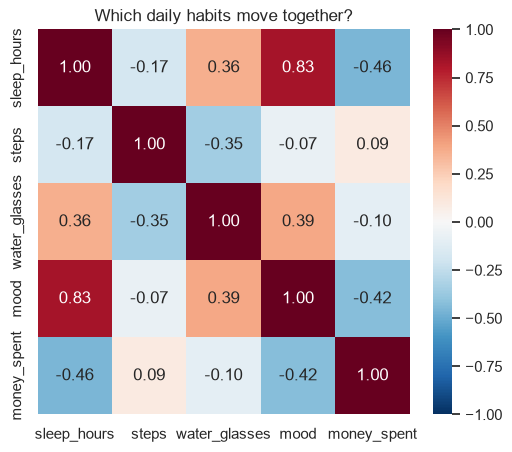

In [20]:
numbers = life[["sleep_hours", "steps", "water_glasses", "mood", "money_spent"]]
plt.figure(figsize=(6, 5))
sns.heatmap(numbers.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0)
plt.title("Which daily habits move together?")
plt.show()

### The code
| Piece | Means |
|---|---|
| `life[[ ... ]]` | pick only the 5 **number** columns (double brackets = a new small table) |
| `numbers.corr()` | compare **every column with every other** → a score from −1 to +1 for each pair |
| `annot=True` | write the numbers inside the squares |
| `fmt=".2f"` | 2 numbers after the dot (0.83) |
| `cmap="RdBu_r"` | colors **Red** and **Blue** ("_r" = reversed → red = plus, blue = minus) |
| `vmin=-1, vmax=1, center=0` | the color scale goes from −1 to +1, and **0 is white** |

### What is the score? — correlation 🚶🚶
**One number that says how much two things move together**, always between −1 and +1. Think of two friends walking:

| Score | Color | The two friends… |
|---|---|---|
| **+1** | 🟥 dark red | walk **together, same direction** ⬆️⬆️ |
| **0** | ⚪ white | **don't care** about each other |
| **−1** | 🟦 dark blue | walk in **opposite directions** ⬆️⬇️ |

0.8 – 0.9 = strong · 0.3 – 0.4 = weak · near 0 = no link.
The **0.83** for sleep & mood is the **stairs** from Lesson 11, turned into one number.

### How to read the table
- Pick a **row** (left) and a **column** (bottom) — where they meet is their score. Row *sleep_hours* × column *mood* = **0.83**.
- The **diagonal** (top-left → bottom-right) is each thing **with itself** → always 1.00. **Ignore it.**
- The table is a **mirror** 🪞: sleep→mood = mood→sleep. Read only one half.

| Pair | Score | Meaning |
|---|---|---|
| sleep & mood | **+0.83** 🟥 | strong: more sleep, better mood |
| sleep & money | −0.46 🟦 | medium? 🤔 |
| mood & money | −0.42 🟦 | medium? 🤔 |
| water & mood | +0.39 | weak? 🤔 |
| sleep & water | +0.36 | weak? 🤔 |
| steps & water | −0.35 | weak? 🤔 |
| everything else | near 0 ⚪ | no link |

### 🚨 The BIG lesson — some links are just luck
We **only hid one secret**: mood depends on sleep. Steps, water and money were made **separately and randomly** — they have **no real link** with anything.
- ✅ **0.83** (sleep & mood) is **real** — we hid it.
- ❌ **−0.46**, **+0.39**, **−0.35**… are **pure luck** 🎲.

How can luck make −0.46? With only **28 days**, random numbers can **look** linked by accident — like flipping a coin 4 times and getting 4 heads 🪙.
And mood & money (−0.42)? It's an **echo** 🔊: mood is made from sleep, so it copies sleep's lucky −0.46.

👩‍🔬 **What a good data scientist does**
1. Strong number + a good reason → probably real ✅
2. Medium/weak number + few days → maybe luck → **get more data** 🔍
3. Always ask: **does it make sense?**

If we trusted the heatmap blindly, we'd believe **5 links. Only 1 is real.** 😱

> ⭐ "Red = they go up together, blue = opposite, white = no link. With few days, some links are just luck."

## 14. `sns.pairplot` — every chart at once

A pair plot compares **every thing with every other thing** in one picture. It's usually the **first chart** a data scientist draws on new data — a "hello, nice to meet you" 👋.

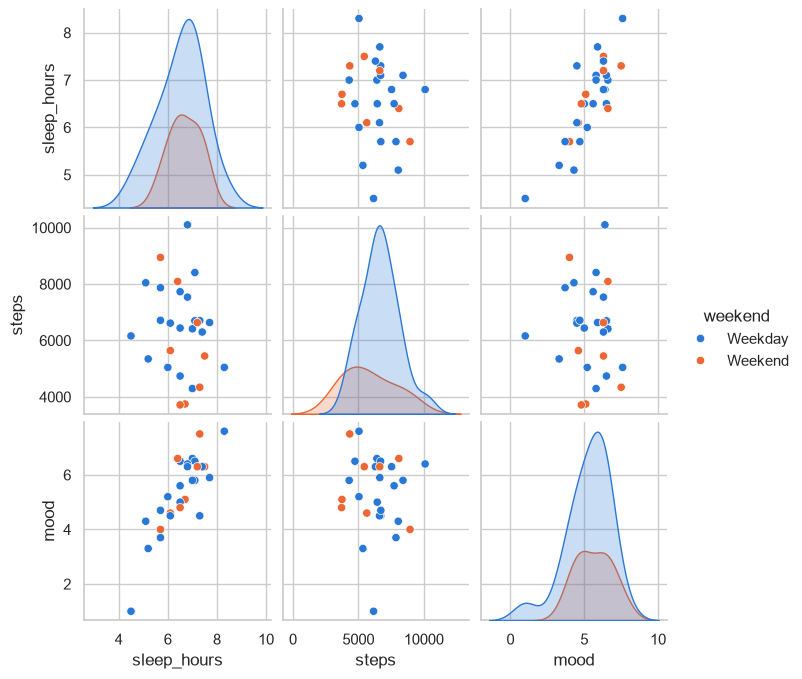

In [21]:
sns.pairplot(life, vars=["sleep_hours", "steps", "mood"], hue="weekend",
             palette={"Weekday": BLUE, "Weekend": ORANGE}, height=2.3)
plt.show()

### The code
| Piece | Means |
|---|---|
| `vars=[...]` | only compare these 3 columns |
| `hue="weekend"` | color by Weekday / Weekend |
| `palette={...}` | 🔵 weekday, 🟠 weekend |
| `height=2.3` | each small chart is 2.3 tall, so they all fit |

No `plt.figure()` here: `pairplot` makes its **own** (big) paper.

### The grid — only 2 kinds of charts
3 things → 3 × 3 = **9 small charts**.
```
                 sleep_hours      steps          mood
 sleep_hours  │  ⛰️ ALONE    │ ⚫ sleep/steps │ ⚫ sleep/mood │
 steps        │ ⚫ steps/sleep│  ⛰️ ALONE     │ ⚫ steps/mood │
 mood         │ ⚫ mood/sleep │ ⚫ mood/steps  │  ⛰️ ALONE    │
```
- ⛰️ **Diagonal = one thing ALONE**, drawn as a **KDE hill** (the sand game). It says *where most of the days are*.
- ⚫ **Everything else = two things TOGETHER**, as a scatter plot. Each dot = one day.
- 🪞 **Mirror:** the top-right charts are the bottom-left ones turned sideways. **Read only the bottom-left half.**

### 🧭 The tour (use this order for ANY pair plot)
**1. Count the boxes** — 3 names → 9 charts.

**2. Hills on the diagonal ↘️**
- 😴 Sleep: the top of the hill is at ~**7 hours** → most nights are about 7 hours.
- 🚶 Steps: 🔵 weekdays peak at ~**6,700**; 🟠 weekends peak at ~**5,000** → weekends **maybe** lazier (only 8 weekend days ⚠️).
- 😊 Mood: peak at ~**6**, and a **tiny bump near 1** → the saddest day.
- The blue hills are **bigger** only because there are **20 weekdays vs 8 weekend days** (more sand). Look at **where** a hill is, not how big.

**3. Dots below the diagonal ↙️**
| Chart | Shape | Meaning |
|---|---|---|
| sleep & steps | ☁️ cloud | no link |
| **sleep & mood** | 🪜 **stairs** ↗️ | **more sleep, better mood** 🎯 the hidden secret again |
| steps & mood | ☁️ cloud | no link |

**4. Colors** — 🔵 and 🟠 are mixed together → weekends follow the same pattern.

### Pair plot vs heatmap — same idea, different answer
**Same idea:** compare every pair, in a grid, with a special diagonal and a mirror.
**Different answer:** the heatmap gives **one number** per pair (a report card 📊); the pair plot shows **all the dots** (the whole exam paper 📚).

⚠️ **Why the pictures matter:** the heatmap number only catches **straight stairs**.
☕ *Coffee and work quality: no coffee → sleepy; 1–2 cups → great; 6 cups → shaking.* The dots make a hill ∩:
```
  work ↑        ⚫ ⚫ ⚫
       │     ⚫         ⚫
       │   ⚫              ⚫
       └──────────────────────→ coffee
```
The heatmap would say **~0 "no link"** ❌ — the pair plot **shows** a clear (curved) link ✅. Technical name: a **non-linear** (here *inverted-U*) relationship.
The pair plot also shows **strange days** that the number hides.

👩‍🔬 **Use both:** heatmap first (quick numbers), then pair plot (check the pictures).

**Tip:** pick **3 – 5 columns**. 5 columns = 25 charts, 10 columns = 100 charts 😵.

> ⭐ "A pair plot shows every thing alone on the diagonal and every pair as dots everywhere else. Tour: hills → dots → colors."

---
# 🎤 How to explain ANY chart to someone

### The 4 steps
| Step | You say |
|---|---|
| 1️⃣ **The question** | "This chart answers: …" |
| 2️⃣ **How to read it** | "At the bottom is… on the left is… each bar / dot / line is…" |
| 3️⃣ **What I see** | "The biggest… the smallest… the most common… the pattern is…" |
| 4️⃣ **What it means** | "So… I should…" — **a chart without a lesson is just a picture** |

### Example — the sleep & mood trend line (Lesson 12)

**⏱️ 30-second version:**
> "This chart shows my sleep and my mood for 28 days. Each dot is one day. The line goes **up**: when I sleep more, I'm usually happier — **every extra hour goes with about 1.4 more mood points**. So if I want to feel better, I should sleep more."

**Full version:**
> 1️⃣ "I wanted to know: does my sleep go together with my mood?"
> 2️⃣ "At the bottom is how many hours I slept; on the left, my mood from 1 to 10. Each dot is one day — for example this one: 4.5 hours, mood 1. The orange line is the best straight line through the dots; the shadow shows how sure we are."
> 3️⃣ "The line goes up. 6 hours ≈ mood 4.6; 8 hours ≈ mood 7.3. The shadow is thin in the middle, where I have many days, and wide at the edges."
> 4️⃣ "Sleep and mood go together, so I should aim for 7–8 hours. **But** it's only 28 days, and it shows they go together — not that sleep causes a good mood."

### Example — the spending histogram (Lesson 9)
> "This chart shows how much I spend per day over 28 days. Each bar is a jar of days by amount: tall bar = many days. Most days I spend **20 – 25 €**, but about **once a week** I spend **50 € or more**. Those big days are where my money really goes — that's what I should watch."

### Questions people often ask
| They ask | You answer |
|---|---|
| "Why aren't all the dots on the line?" | "Life has surprises. The line is the general direction." |
| "What's the shadow / black line?" | "How sure we are. Thin = sure; wide = not sure, because there's less data there." |
| "So sleep **makes** you happy?" | "Not proven — they go **together**. Maybe happy days help me sleep, or no stress helps both." |
| "Why not just tell me the average?" | "The average **hides the story**. 30 €/day sounds normal, but the chart shows two kinds of days: normal days and big days." |
| "What if you sleep 12 hours?" | "I can't say — I only trust the line where I have dots." |
| "Is this real data?" | "It's practice data. I hid a rule (+1.5 mood per hour) to test the chart, and the chart found 1.36." |

### 🌟 3 tips to explain like a pro
1. **👆 Point while you talk** — people follow your finger.
2. **📖 Give one real example** — "this dot: 4.5 hours of sleep, mood 1".
3. **⚠️ Always add one "but"** — "but it's only 28 days". It shows you're honest and careful.

> ⭐ "Question → how to read it → what I see → what it means. Point, give one example, and always add one 'but'."

## 🧠 Golden rules of a good chart
1. **One chart = one question.** Write the question as the title.
2. **Always label** both axes, **with units** (hours, minutes, €).
3. **Bars start at zero.** Otherwise small differences look huge (that's cheating!).
4. **Fewer colors.** Use color only when it means something (like `hue`).
5. **No pie charts with many slices.** A bar chart is easier to read.
6. **Tell the story in one sentence** under the chart: *"I walk less on Sundays."*
7. **Few data points = be careful.** Show how sure you are (error bars, shadows) and say "but".
8. **Together ≠ causes.**

## ⚠️ Fixes for old Seaborn code (e.g. in `5. Matplotlib and Seaborn.ipynb`)

| Old code | New code |
|---|---|
| `sns.kdeplot(data[col], shade=True)` | `sns.kdeplot(data[col], fill=True)` |
| `sns.distplot(data[col], hist=False)` | `sns.kdeplot(data[col])` |
| `sns.distplot(data[col])` | `sns.histplot(data[col], kde=True)` |
| `sns.set()` | `sns.set_theme()` |

## 📖 Glossary — easy words and technical words

| Easy words | Technical word |
|---|---|
| Information you write down | **data** |
| A table with rows (days) and columns (things measured) | **DataFrame** |
| Invented practice data | **pretend / synthetic data** |
| Secret code that makes random numbers repeat | **seed** |
| The paper / the drawing box | **figure (`fig`) / axes (`ax`)** |
| The two rulers | **x-axis** (bottom) / **y-axis** (left) |
| The little labels on a ruler | **ticks** (`xticks`, `yticks`) |
| The color key | **legend** |
| Color each group differently | **`hue`** |
| The favorite number / the middle | **mean** (average) |
| How far numbers usually go from the middle | **standard deviation** |
| The middle day when lined up | **median** |
| The shape the data makes | **distribution** |
| A round hill, same on both sides | **normal distribution / bell curve** |
| The top of the hill | **peak / mode** |
| Jars on a histogram | **bins** |
| The smooth hill line | **KDE** (kernel density estimate) / **density curve** |
| The middle half of the days (the box) | **interquartile range (IQR)** |
| A strange day | **outlier** |
| The black line on a bar / the shadow on a trend line | **error bar / 95% confidence interval** |
| The bag game | **bootstrapping** |
| The best straight line through dots | **regression line** (trend line) |
| How much the line goes up per step | **slope** |
| How much two things move together (−1 to +1) | **correlation** |
| Dots in a curve, not a straight line | **non-linear relationship** |
| Going together doesn't mean one causes the other | **correlation is not causation** |

---
# 📅 Daily Activities — 14 Days to Confidence

Do **one small thing each day** (20–40 minutes). Small every day beats big once a week.

| Day | Learn | Daily-life activity (use YOUR own data) |
|---|---|---|
| 1 | Paper–draw–name recipe, line chart | Write down your wake-up time for the last 7 days. Make a line chart. |
| 2 | Bar chart, `barh` | List what you spent money on this week. Make a bar chart by category (in €). |
| 3 | Histogram | Time how long tasks take today (shower, breakfast, travel). Plot a histogram. |
| 4 | Scatter plot | For 7 days: hours on your phone vs hours of sleep. Scatter them. Do they move together? |
| 5 | Subplots + saving | Put Days 1–4 on one page (2×2). Save it as a PNG. |
| 6 | **Explain day** | Show your 2×2 picture to a friend or family member. Explain each chart with the 4 steps. |
| 7 | Rest + review | Re-read the Big Idea, the Golden rules and the Glossary. Fix your old notebook with the table above. |
| 8 | `sns.lineplot`, `sns.barplot` | Redo Days 1 and 2 with Seaborn. Which was easier? |
| 9 | `sns.histplot`, `kde=True` | Track the temperature (weather app) for 14 days. Histogram + KDE. |
| 10 | `sns.boxplot` | Your steps (phone health app) by day of week. Which day is laziest? 😄 |
| 11 | `hue` | Make a table of meals: cost in €, home vs outside. Scatter with `hue`. |
| 12 | `sns.heatmap` | Build a table of 5 habits for 2 weeks. Heatmap of `.corr()`. Which links might be luck? |
| 13 | Real dataset | `sns.load_dataset("tips")` — restaurant bills and tips. Do bigger bills get bigger tips? |
| 14 | **Mini project** | Pick one question about your life. Collect 2 weeks of data. Make 3 charts + 3 sentences. Share it (LinkedIn/GitHub). |

### Every single day (5 minutes) ⏱️
- ✍️ **Write down 3 numbers** from your day (sleep, steps, money in €, water — anything). This becomes your own dataset.
- 👀 **Look at one chart** in the news or on social media. Ask: *What question does it answer? Is it honest?*
- 🗣️ **Explain one chart out loud** in one sentence, as if to a 7-year-old.

> 🏆 **The secret of the best data scientists:** not knowing every function — it's asking a clear question,
> picking the right picture, and explaining it so simply that anyone understands.

## 🏁 Your turn — starter code for Day 1

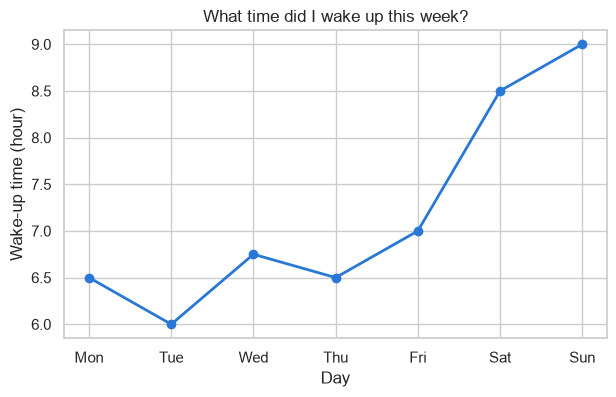

In [ ]:
# Replace these with YOUR real wake-up times (in hours, e.g. 6.5 = 6:30)
my_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wake_up = [6.5, 6.0, 6.75, 6.5, 7.0, 8.5, 9.0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(my_days, wake_up, color=BLUE, marker="o", linewidth=2)
ax.set_title("What time did I wake up this week?")
ax.set_xlabel("Day")
ax.set_ylabel("Wake-up time (hour)")
plt.show()
# One-sentence story: I was able to sleep in on the weekend, but I had to wake up early for work during the week.